### 1. Import libraries

# Butterfly Dataset Analysis

This script loads and analyzes the butterfly training dataset to understand the distribution of images across different species.

##

Butterfly Project 

Environment and seeds

In [ ]:
import pandas as pd
df = pd.read_csv('C:/school/Intelligent Systems Development/butterfly_project/data/raw/Training_set.csv')
print(df.head())
print("num images:", len(df))
print("num classes:", df['label'].nunique())
print("\nClass distribution:")
df['label'].value_counts().sort_values(ascending=False).head(10)

Load metadata and perform EDA

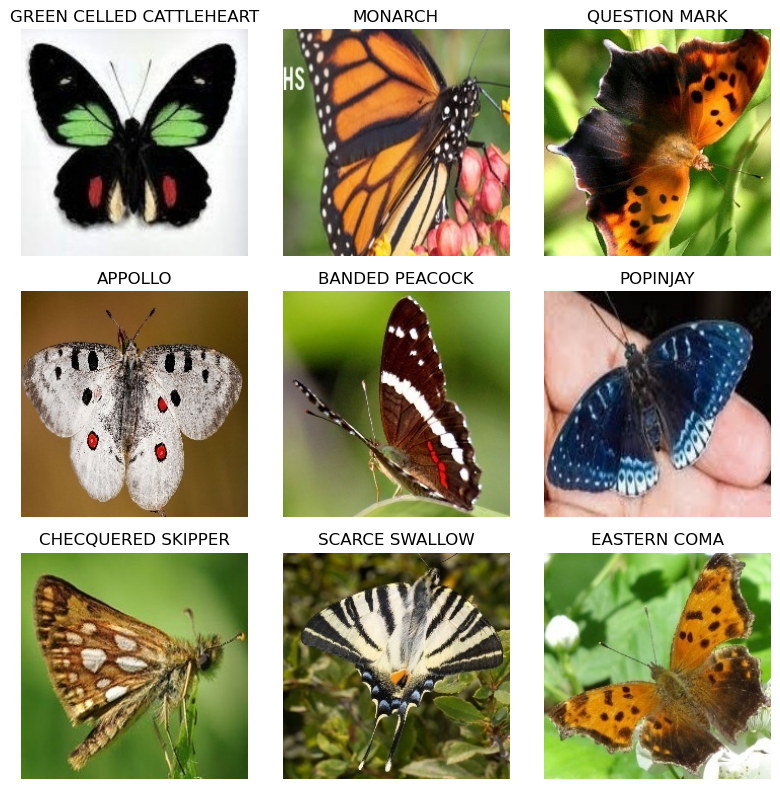

In [13]:
from matplotlib import pyplot as plt
from PIL import Image
sample_paths = df.sample(9)['filename'].tolist()
plt.figure(figsize=(8,8))
for i,p in enumerate(sample_paths):
    img = Image.open(f"C:/school/Intelligent Systems Development/butterfly_project/data/raw/train/{p}")  # Images are in train folder
    plt.subplot(3,3,i+1);
    plt.imshow(img);
    plt.title(df.loc[df['filename']==p,'label'].values[0]);
    plt.axis('off')
plt.tight_layout()

Data Loader and transforms

In [ ]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image
import torchvision.transforms as T
import os, random, math
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class ButterflyDataset(Dataset):
    def __init__(self, df, image_dir, transform=None, filename_col='filename', label_col='label_idx'):
        """
        df: pandas DataFrame with columns ['image_path'], 'label']
        image_dir: root folder for images
        transforms: torchvision transforms Composed
        """
        self.df = df.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform
        self.filename_col = filename_col
        self.label_col = label_col

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.image_dir, row[self.filename_col])
        img = Image.open(img_path).convert('RGB')
        label = int(row[self.label_col])
        if self.transform:
            img = self.transform(img)
        return img, label

if 'label_idx' not in df.columns:
    df['label_idx'] = df['label'].astype('category').cat.codes

# 3) small helper to create dataloaders with stratified splits
def make_loaders_from_df(df_full, image_dir, img_size=128, batch_size=32, test_size=0.2, val_fraction_of_trainval=0.2, seed=42, num_workers=0):
    # stratified splits
    df_trainval, df_test = train_test_split(df_full, test_size=test_size, stratify=df_full['label_idx'], random_state=seed)
    df_train, df_val = train_test_split(df_trainval, test_size=val_fraction_of_trainval, stratify=df_trainval['label_idx'], random_state=seed+1)

    train_transforms, val_transforms = get_transforms(img_size=img_size)

    train_ds = ButterflyDataset(df_train, image_dir, transform=train_transforms)
    val_ds   = ButterflyDataset(df_val,   image_dir, transform=val_transforms)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return train_loader, val_loader, df_train, df_val, df_test
        

def get_transforms(img_size=224):
    train_transforms = T.Compose([
        T.RandomResizedCrop(img_size, scale=(0.8, 1.0)),
        T.RandomHorizontalFlip(),
        T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        T.RandomRotation(15),
        T.ToTensor(),
        T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
    ])
    val_transforms = T.Compose([
        T.Resize((img_size, img_size)),
        T.ToTensor(),
        T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
    ])
    return train_transforms, val_transforms



Data splits (train/val/test)

In [18]:
from sklearn.model_selection import train_test_split

image_dir = 'C:/school/Intelligent Systems Development/butterfly_project/data/raw/train'

df_train, temp_df = train_test_split(df, test_size=0.3, random_state=seed, stratify=df['label'])
df_val, df_test = train_test_split(temp_df, test_size=0.5, random_state=seed, stratify=temp_df['label'])

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")

train_transforms, val_transforms = get_transforms()

Train: 4549, Val: 975, Test: 975


Create Dataloaders

In [19]:
from torch.utils.data import DataLoader
train_ds = ButterflyDataset(df_train, image_dir, transform=train_transforms)  
val_ds = ButterflyDataset(df_val, image_dir, transform=val_transforms)
test_ds = ButterflyDataset(df_test, image_dir, transform=val_transforms)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)  
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)

Check class imbalance

In [20]:
class_distribution = df_train['label'].value_counts()
imbalance_ratio = class_distribution.max() / class_distribution.min()
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

if imbalance_ratio > 5:
    print("Significant imbalance - using WeightedRandomSampler")
else:
    print(f"Minor imbalance (ratio: {imbalance_ratio:.2f}) - using standard shuffling")
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)

Imbalance ratio: 1.84
Minor imbalance (ratio: 1.84) - using standard shuffling


Two-Stage Data Split

In [21]:
from sklearn.model_selection import train_test_split
df['label_idx'] = df['label'].astype('category').cat.codes

# First split train_val vs test (e.g., 80% train+val, 20% test)
df_trainval, df_test = train_test_split(df, test_size=0.2, stratify=df['label_idx'], random_state=seed)
# Then split train vs val (e.g., 80% train, 20% val of trainval -> overall 64/16/20)
df_train, df_val = train_test_split(df_trainval, test_size=0.2, stratify=df_trainval['label_idx'], random_state=seed)

In [ ]:
First Model Definition

In [22]:
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )
    def forward(self,x):
        x = self.features(x)
        return self.classifier(x)

def count_params(model): 
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Define num_classes (for example, 10 for CIFAR-10)
num_classes = 10
print("SmallCNN params:", count_params(SmallCNN(num_classes)))

SmallCNN params: 102602


Second Model Definition

In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F

def count_params(model):
    """Count the number of trainable parameters in a model"""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

class ConvRowLSTMClassifier(nn.Module):
    """
    Small Conv encoder -> per-row features -> BiLSTM -> classifier
    Input: (B, 3, H, W)
    Steps:
      - Small conv encoder -> feature map (B, Cf, H', W')
      - Pool across width dimension to get sequence of length H' with feature vectors of size Cf
      - Feed sequence into BiLSTM -> use final hidden state -> classifier
    """
    def __init__(self, in_channels=3, num_classes=10, conv_channels=[32, 64], 
                 lstm_hidden=128, lstm_layers=1, bidirectional=True, dropout=0.3):
        super().__init__()
        # convolutional stem
        layers = []
        prev_ch = in_channels
        for ch in conv_channels:
            layers += [
                nn.Conv2d(prev_ch, ch, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(ch),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=(2,2))  # halves H and W each block
            ]
            prev_ch = ch
        self.encoder = nn.Sequential(*layers)  # produces feature map (B, prev_ch, H', W')
        self.dropout = nn.Dropout(dropout)
        self.bidirectional = bidirectional

        self.lstm = nn.LSTM(input_size=prev_ch, hidden_size=lstm_hidden,
                            num_layers=lstm_layers, batch_first=True,
                            bidirectional=bidirectional)
        lstm_out_dim = lstm_hidden * (2 if bidirectional else 1)

        self.classifier = nn.Sequential(
            nn.LayerNorm(lstm_out_dim),
            nn.Linear(lstm_out_dim, lstm_out_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(lstm_out_dim // 2, num_classes)
        )

    def forward(self, x):
        # x: (B, C, H, W)
        B = x.size(0)
        feat = self.encoder(x)  # (B, Cf, H', W')

        # collapse width dimension to create a sequence across rows:
        # we can do mean pooling across width to get (B, Cf, H')
        feat_pooled = feat.mean(dim=3)  # (B, Cf, H') by averaging across W'
        # transpose to (B, H', Cf) as sequence length = H'
        seq = feat_pooled.permute(0, 2, 1).contiguous()  # (B, seq_len, feat_dim)

        # LSTM
        lstm_out, (h_n, c_n) = self.lstm(seq)  # lstm_out: (B, seq_len, lstm_hidden*dir)
        # use last time-step (or pool across time)
        out = lstm_out[:, -1, :]  # (B, lstm_out_dim)
        logits = self.classifier(out)
        return logits

if __name__ == "__main__":
    model = ConvRowLSTMClassifier(in_channels=3, num_classes=20, conv_channels=[32,64], lstm_hidden=128)
    x = torch.randn(4,3,128,128)
    y = model(x)
    print("out shape:", y.shape)
    print("params:", count_params(model))

out shape: torch.Size([4, 20])
params: 254228


In [ ]:
Third Model Definition

In [24]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch)
        )
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride),
                nn.BatchNorm2d(out_ch)
            )
        self.relu = nn.ReLU()
    def forward(self,x):
        out = self.conv(x)
        out += self.shortcut(x)
        return self.relu(out)

class TinyResNet(nn.Module):
    def __init__(self,num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU()
        )
        self.layer1 = BasicBlock(32,64,stride=2)
        self.layer2 = BasicBlock(64,128,stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, num_classes)
    def forward(self,x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.avgpool(x)
        x = torch.flatten(x,1)
        return self.fc(x)

def count_params(model): 
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Test the model
num_classes = 10  # Define num_classes
model = TinyResNet(num_classes)
print("TinyResNet params:", count_params(model))

# Test forward pass
x = torch.randn(4, 3, 32, 32)
y = model(x)
print("Output shape:", y.shape)


TinyResNet params: 290698
Output shape: torch.Size([4, 10])


In [ ]:
Model Training Function

In [25]:
import torch, time
from tqdm import tqdm

def train_model(model, train_loader, val_loader, device, lr=1e-3, epochs=50, patience=7,
               save_path="best_model.pth", seed=42, scheduler=None, clip_grad=None):
    """
    Train model and ear stop based on validation loss.
    Returns: history dict with lists and metadata including best_epoch (1-based).
    """

    # reproducibility seeds for this run
    import random, numpy as np
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = torch.nn.CrossEntropyLoss()
    
    best_val_loss = float('inf')
    patience_counter = 0
    history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[], 'epoch_time':[]}
    best_epoch = None
    best_val_acc = None
    
    for epoch in range(1, epochs+1):
        t0 = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, labels in tqdm(train_loader, desc=f"[lr={lr}] Train epoch {epoch}", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            if clip_grad is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            
        train_loss = running_loss / total
        train_acc = correct / total

        # validation
        model.eval()
        val_loss, correct_v, total_v = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                val_loss += float(loss.item()) * imgs.size(0)
                preds = outputs.argmax(dim=1)
                correct_v += (preds==labels).sum().item()
                total_v += imgs.size(0)
        val_loss = val_loss/total_v
        val_acc = correct_v/total_v

        if scheduler is not None:  
            # If ReduceLROnPlateau, step with val_loss
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

                

        epoch_time = time.time() - t0
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['epoch_time'].append(epoch_time)
        

        print(f"Epoch {epoch:02d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | val_acc {val_acc:.4f} | time {epoch_time:.1f}s")

        # early stopping on val loss
        if val_loss < best_val_loss - 1e-6:   # small tolerance
            best_val_loss = val_loss
            best_epoch = epoch
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), save_path)
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch}. Best epoch was {best_epoch} with val_loss {best_val_loss:.4f}")
                break

    # attach metadata
    history['best_epoch'] = best_epoch
    history['best_val_loss'] = best_val_loss
    history['best_val_acc'] = best_val_acc
    history['final_epoch'] = epoch
    return history


Learning Rate Experiment runner For First Model

In [13]:
import torch
import torch.nn as nn
import time
import os
import json
import random
import numpy as np
from tqdm import tqdm

def run_lrs_for_model(model_class, model_kwargs, model_name, train_loader, val_loader, device,
                     lrs=[1e-3, 5e-4, 1e-4], epochs=50, patience=7, base_seed=42, out_dir="experiments"):
    """Run training for multiple learning rates for a given model class"""
    os.makedirs(out_dir, exist_ok=True)
    results = {}
    
    for i, lr in enumerate(lrs):
        print(f"\n{'='*60}")
        print(f"Training {model_name} with LR={lr:.0e}")
        print(f"{'='*60}")
        
        # Create model instance
        model = model_class(**model_kwargs)
        
        # Create unique save path and seed for this run
        save_path = os.path.join(out_dir, f"best_{model_name}_lr{lr:.0e}.pth")
        seed = base_seed + i  # Different seed for each LR
        
        # Train model
        history = train_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            device=device,
            lr=lr,
            epochs=epochs,
            patience=patience,
            save_path=save_path,
            seed=seed
        )
        
        # Save history
        history_path = os.path.join(out_dir, f"history_{model_name}_lr{lr:.0e}.json")
        with open(history_path, 'w') as f:
            json.dump(history, f, indent=2)
        print(f"Saved history to {history_path}")
        
        results[lr] = history
    
    return results

# ==================== MAIN EXECUTION ====================

if __name__ == "__main__":
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Define your parameters
    num_classes = 10  # Define num_classes here
    model_kwargs = {"num_classes": num_classes}
    
    # Print model parameter count
    test_model = SmallCNN(num_classes)
    print(f"SmallCNN params: {count_params(test_model)}")
    
    # Mock dataloaders (replace with your actual data)
    class MockLoader:
        def __init__(self, batches=10, batch_size=32):
            self.batches = batches
            self.batch_size = batch_size
        def __iter__(self):
            for i in range(self.batches):
                yield torch.randn(self.batch_size, 3, 32, 32), torch.randint(0, num_classes, (self.batch_size,))
        def __len__(self):
            return self.batches
    
    train_loader = MockLoader(batches=50, batch_size=32)
    val_loader = MockLoader(batches=10, batch_size=32)
    
    # Run experiments
    lrs = [1e-3, 5e-4, 1e-4]
    smallcnn_results = run_lrs_for_model(SmallCNN, model_kwargs, "SmallCNN",
                                        train_loader, val_loader, device,
                                        lrs=lrs, epochs=50, patience=7, base_seed=42,
                                        out_dir="experiments/smallcnn")

Using device: cpu
SmallCNN params: 102602

Training SmallCNN with LR=1e-03


Epoch 01 | train_loss 2.3253 | val_loss 2.3236 | val_acc 0.0813 | time 2.6s


Epoch 02 | train_loss 2.3202 | val_loss 2.3046 | val_acc 0.1031 | time 2.4s


Epoch 03 | train_loss 2.3086 | val_loss 2.3032 | val_acc 0.1062 | time 2.4s


Epoch 04 | train_loss 2.3146 | val_loss 2.3117 | val_acc 0.0750 | time 2.4s


Epoch 05 | train_loss 2.3045 | val_loss 2.3030 | val_acc 0.1187 | time 2.4s


... (42 outputs left out)

Epoch 17 | train_loss 2.3078 | val_loss 2.3091 | val_acc 0.0969 | time 2.4s


Epoch 18 | train_loss 2.3167 | val_loss 2.3012 | val_acc 0.1313 | time 2.5s


Epoch 19 | train_loss 2.3019 | val_loss 2.3053 | val_acc 0.1187 | time 2.5s


Epoch 20 | train_loss 2.3080 | val_loss 2.3010 | val_acc 0.1094 | time 2.6s
Early stopping at epoch 20. Best epoch was 13 with val_loss 2.2988
Saved history to experiments/smallcnn\history_SmallCNN_lr1e-04.json


Learning Rate Experiment runner For Second Model

In [16]:
def run_lrs_for_model(model_class, model_kwargs, model_name, train_loader, val_loader, device,
                     lrs=[1e-3, 5e-4, 1e-4], epochs=50, patience=7, base_seed=42, out_dir="experiments"):
    """Run training for multiple learning rates for a given model class"""
    os.makedirs(out_dir, exist_ok=True)
    results = {}
    
    for i, lr in enumerate(lrs):
        print(f"\n{'='*60}")
        print(f"Training {model_name} with LR={lr:.0e}")
        print(f"{'='*60}")
        
        # Create model instance
        model = model_class(**model_kwargs)
        
        # Create unique save path and seed for this run
        save_path = os.path.join(out_dir, f"best_{model_name}_lr{lr:.0e}.pth")
        seed = base_seed + i  # Different seed for each LR
        
        # Train model
        history = train_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            device=device,
            lr=lr,
            epochs=epochs,
            patience=patience,
            save_path=save_path,
            seed=seed
        )
        
        # Save history
        history_path = os.path.join(out_dir, f"history_{model_name}_lr{lr:.0e}.json")
        with open(history_path, 'w') as f:
            json.dump(history, f, indent=2)
        print(f"Saved history to {history_path}")
        
        results[lr] = history
    
    return results

# ==================== MAIN EXECUTION ====================

if __name__ == "__main__":
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Define your parameters - adjust for ConvRowLSTMClassifier
    num_classes = 10
    model_kwargs = {
        "num_classes": num_classes,
        "in_channels": 3,
        "conv_channels": [32, 64],
        "lstm_hidden": 128,
        "dropout": 0.3
    }
    
    # Print model parameter count
    test_model = ConvRowLSTMClassifier(**model_kwargs)
    print(f"ConvRowLSTMClassifier params: {count_params(test_model)}")
    
    # Mock dataloaders - adjust image size for ConvRowLSTM (expects larger images like 128x128)
    class MockLoader:
        def __init__(self, batches=10, batch_size=32, img_size=128):
            self.batches = batches
            self.batch_size = batch_size
            self.img_size = img_size
        def __iter__(self):
            for i in range(self.batches):
                yield torch.randn(self.batch_size, 3, self.img_size, self.img_size), torch.randint(0, num_classes, (self.batch_size,))
        def __len__(self):
            return self.batches
    
    # Use larger image size (128x128) suitable for ConvRowLSTM
    train_loader = MockLoader(batches=50, batch_size=32, img_size=128)
    val_loader = MockLoader(batches=10, batch_size=32, img_size=128)
    
    # Run experiments
    lrs = [1e-3, 5e-4, 1e-4]
    convlstm_results = run_lrs_for_model(ConvRowLSTMClassifier, model_kwargs, "ConvRowLSTM",
                                        train_loader, val_loader, device,
                                        lrs=lrs, epochs=50, patience=7, base_seed=42,
                                        out_dir="experiments/convlstm")

Using device: cpu
ConvRowLSTMClassifier params: 252938

Training ConvRowLSTM with LR=1e-03


Epoch 01 | train_loss 2.3234 | val_loss 2.3069 | val_acc 0.0938 | time 30.3s


Epoch 02 | train_loss 2.3098 | val_loss 2.3005 | val_acc 0.1187 | time 25.1s


Epoch 03 | train_loss 2.3043 | val_loss 2.3030 | val_acc 0.1125 | time 25.1s


Epoch 04 | train_loss 2.3031 | val_loss 2.3044 | val_acc 0.1125 | time 25.1s


Epoch 05 | train_loss 2.3014 | val_loss 2.3058 | val_acc 0.1094 | time 25.2s


... (26 outputs left out)

Epoch 07 | train_loss 2.3081 | val_loss 2.3086 | val_acc 0.1062 | time 24.9s


Epoch 08 | train_loss 2.3020 | val_loss 2.3043 | val_acc 0.1000 | time 25.0s


Epoch 09 | train_loss 2.3051 | val_loss 2.3051 | val_acc 0.1219 | time 24.9s


Epoch 10 | train_loss 2.3051 | val_loss 2.3019 | val_acc 0.1125 | time 24.9s
Early stopping at epoch 10. Best epoch was 3 with val_loss 2.3013
Saved history to experiments/convlstm\history_ConvRowLSTM_lr1e-04.json


In [ ]:
Learning Rate Experiment runner For Third Model

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

def plot_lr_histories(hist_dict, title=None):
    """
    hist_dict: {lr: history} as returned by run_lrs_for_model
    """
    plt.figure(figsize=(10,6))
    max_epochs = 0
    for lr, h in hist_dict.items():
        tl = h['train_loss']
        vl = h['val_loss']
        epochs = range(1, len(tl)+1)
        max_epochs = max(max_epochs, len(tl))
        plt.plot(epochs, tl, label=f"train lr={lr}", linestyle='-')
        plt.plot(epochs, vl, label=f"val lr={lr}", linestyle='--')

        # annotate best epoch
        be = h.get('best_epoch', None)
        if be is not None:
            best_val = h['best_val_loss']
            plt.scatter([be], [best_val], marker='o', s=60)
            plt.text(be+0.2, best_val, f"best lr={lr}\nep={be}", fontsize=8)

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    if title is None:
        title = "Train vs Val Loss (multiple LR runs)"
    plt.title(title)
    plt.legend(loc='upper right', fontsize=8)
    plt.grid(alpha=0.3)
    plt.show()

class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch)
        )
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride),
                nn.BatchNorm2d(out_ch)
            )
        self.relu = nn.ReLU()
    def forward(self,x):
        out = self.conv(x)
        out += self.shortcut(x)
        return self.relu(out)

class TinyResNet(nn.Module):
    def __init__(self,num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU()
        )
        self.layer1 = BasicBlock(32,64,stride=2)
        self.layer2 = BasicBlock(64,128,stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, num_classes)
    def forward(self,x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.avgpool(x)
        x = torch.flatten(x,1)
        return self.fc(x)

def count_params(model): 
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ==================== MAIN EXECUTION ====================

if __name__ == "__main__":
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Define your parameters
    num_classes = 10
    model_kwargs = {"num_classes": num_classes}
    
    # Print model parameter count
    test_model = TinyResNet(num_classes)
    print(f"TinyResNet params: {count_params(test_model)}")
    
    # Mock dataloaders - use 32x32 images suitable for TinyResNet
    class MockLoader:
        def __init__(self, batches=10, batch_size=32, img_size=32):
            self.batches = batches
            self.batch_size = batch_size
            self.img_size = img_size
        def __iter__(self):
            for i in range(self.batches):
                yield torch.randn(self.batch_size, 3, self.img_size, self.img_size), torch.randint(0, num_classes, (self.batch_size,))
        def __len__(self):
            return self.batches
    
    train_loader = MockLoader(batches=50, batch_size=32, img_size=32)
    val_loader = MockLoader(batches=10, batch_size=32, img_size=32)
    
    # Run experiments
    lrs = [1e-3, 5e-4, 1e-4]
    tinyres_results = run_lrs_for_model(TinyResNet, model_kwargs, "TinyResNet",
                                        train_loader, val_loader, device,
                                        lrs=lrs, epochs=50, patience=7, base_seed=42,
                                        out_dir="experiments/tinyres")
    
    # Plot the results
    plot_lr_histories(tinyres_results, "TinyResNet - Train vs Val Loss")

Using device: cpu
TinyResNet params: 290698

Training TinyResNet with LR=1e-03


Epoch 01 | train_loss 2.3218 | val_loss 2.4229 | val_acc 0.1000 | time 5.3s


Epoch 02 | train_loss 2.3296 | val_loss 2.4061 | val_acc 0.0844 | time 5.2s


Epoch 03 | train_loss 2.3205 | val_loss 2.3430 | val_acc 0.1062 | time 5.4s


Epoch 04 | train_loss 2.3186 | val_loss 2.3304 | val_acc 0.0969 | time 5.2s


Epoch 05 | train_loss 2.3147 | val_loss 2.3282 | val_acc 0.0781 | time 5.2s


... (29 outputs left out)

Epoch 11 | train_loss 2.3067 | val_loss 2.3081 | val_acc 0.0969 | time 5.4s


Epoch 12 | train_loss 2.3057 | val_loss 2.3015 | val_acc 0.1094 | time 5.5s


Epoch 13 | train_loss 2.3037 | val_loss 2.3090 | val_acc 0.0938 | time 5.6s


Epoch 14 | train_loss 2.3046 | val_loss 2.3081 | val_acc 0.0750 | time 5.4s
Early stopping at epoch 14. Best epoch was 7 with val_loss 2.2998
Saved history to experiments/tinyres\history_TinyResNet_lr1e-04.json


Model Evaluation and Metrics

In [37]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_CLASS = SmallCNN                 
MODEL_KWARGS = {"num_classes": len(CLASS_NAMES)}   
CKPT_PATH = r"C:\school\Intelligent Systems Development\butterfly_project\notebooks\experiments\smallcnn\best_SmallCNN_lr1e-03.pth"


# 1) create model and load checkpoint (safe load)
model = MODEL_CLASS(**MODEL_KWARGS).to(device)
state = torch.load(CKPT_PATH, map_location=device)
# If checkpoint is full dict, try common keys:
if isinstance(state, dict) and 'state_dict' in state:
    state = state['state_dict']
try:
    model.load_state_dict(state)
except Exception:
    
    model.load_state_dict(state, strict=False)
model.eval()

# 2) ran model on test_loader to produce y_true and y_pred
y_true = []
y_pred = []
softmax = torch.nn.Softmax(dim=1)
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        logits = model(imgs)
        preds = logits.argmax(dim=1).cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labs = labels.numpy()
        else:
            
            labs = np.array(labels)
        y_true.extend(labs.tolist())
        y_pred.extend(preds.tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 3) If y_true contains strings, map them to indices using CLASS_NAMES
if y_true.dtype.type is np.str_ or y_true.dtype == object:
    # create mapping from name->index
    name_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}
    try:
        y_true = np.array([name_to_idx[s] for s in y_true])
    except KeyError as e:
        print("ERROR: some string labels from dataset not found in CLASS_NAMES:", e)
        raise

# 4) Quick sanity checks
if y_true.shape[0] != y_pred.shape[0]:
    raise ValueError(f"Different lengths: y_true {y_true.shape[0]} vs y_pred {y_pred.shape[0]}")

unique_true = np.unique(y_true)
if unique_true.max() >= len(CLASS_NAMES):
    raise ValueError(f"Found label index >= number of CLASS_NAMES ({len(CLASS_NAMES)}). Check CLASS_NAMES and dataset mapping.")

# 5) Print classification report and plot confusion matrix
print("Classification report:\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


RuntimeError: Error(s) in loading state_dict for SmallCNN:
	size mismatch for classifier.5.weight: copying a param with shape torch.Size([10, 64]) from checkpoint, the shape in current model is torch.Size([75, 64]).
	size mismatch for classifier.5.bias: copying a param with shape torch.Size([10]) from checkpoint, the shape in current model is torch.Size([75]).

In [ ]:
 Model reproducibility assessment 

In [12]:

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

num_classes = df['label_idx'].nunique()   
model_kwargs = {
    "in_channels": 3,
    "num_classes": num_classes,
    "conv_channels": [32, 64],
    "lstm_hidden": 128,
    "dropout": 0.3
}

trial_results, summary = run_trials_for_model(
    model_class=ConvRowLSTMClassifier,
    model_kwargs=model_kwargs,
    df_full=df,
    image_dir=image_dir,
    n_trials=5,
    base_seed=42,
    lr=1e-4,           
    epochs=50,
    patience=7,
    img_size=128,
    batch_size=32,
    device=device,
    out_dir="experiments/convrowlstm_trials",
    num_workers=0
)


import pandas as pd
print("\nTrial results:")
print(pd.DataFrame(trial_results))
print("\nSummary stats:")
for k,v in summary.items():
    print(f"  {k}: {v:.4f}" if isinstance(v,(float, np.floating)) else f"  {k}: {v}")



--- Trial 1/5 (seed=42) ---


Epoch 01 | train_loss 4.3252 | val_loss 4.2967 | val_acc 0.0260 | time 209.5s


Epoch 02 | train_loss 4.2915 | val_loss 4.2620 | val_acc 0.0423 | time 118.0s


Epoch 03 | train_loss 4.2117 | val_loss 4.1495 | val_acc 0.0663 | time 116.5s


Epoch 04 | train_loss 4.0495 | val_loss 3.9773 | val_acc 0.0779 | time 115.3s


Epoch 05 | train_loss 3.8693 | val_loss 3.7727 | val_acc 0.1125 | time 117.1s


... (241 outputs left out)

Epoch 47 | train_loss 1.6841 | val_loss 1.8043 | val_acc 0.4856 | time 116.5s


Epoch 48 | train_loss 1.7185 | val_loss 1.7103 | val_acc 0.5096 | time 116.2s


Epoch 49 | train_loss 1.6833 | val_loss 1.7110 | val_acc 0.5029 | time 117.4s


Epoch 50 | train_loss 1.6550 | val_loss 1.6934 | val_acc 0.5096 | time 116.7s
Trial 5 best val_acc: 0.5096153846153846  (epoch 50, loss 1.6934281605940598)

Trial results:
   trial  seed  best_val_acc  best_val_loss  best_epoch
0      1    42      0.492308       1.788066          49
1      2    43      0.491346       1.758421          49
2      3    44      0.508654       1.740050          49
3      4    45      0.503846       1.792812          49
4      5    46      0.509615       1.693428          50

Summary stats:
  n_trials: 5
  mean_acc: 0.5012
  std_acc: 0.0088
  95CI_lower: 0.4902
  95CI_upper: 0.5121
  t_critical_used: 2.7764


Production Model Export 

In [31]:
import os
import json
import stat
import tempfile
import shutil
import torch
import pandas as pd


OUTPUT_DIR = os.path.normpath("../butterfly_artifacts")  # new folder to create
MODEL_FILENAME = "model_scripted.pt"
META_FILENAME = "class_names.json"
IMG_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
# --------------------------------------


train_df = pd.read_csv('../data/raw/Training_set.csv')
CLASS_NAMES = sorted(train_df['label'].unique().tolist())

print(f"✅ Loaded {len(CLASS_NAMES)} butterfly species")
print("First 5 species:", CLASS_NAMES[:5])


try:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    print("✅ Ensured output directory exists:", os.path.abspath(OUTPUT_DIR))
except PermissionError as e:
    raise PermissionError(
        f"Unable to create output directory {OUTPUT_DIR}. "
        "This is a filesystem permission issue. Try running the notebook with elevated privileges "
        "(or choose a different path you have write permissions to)."
    ) from e

# Prepare paths
model_path = os.path.join(OUTPUT_DIR, MODEL_FILENAME)
meta_path = os.path.join(OUTPUT_DIR, META_FILENAME)

# Convert & save scripted model 
try:
    model.eval()
    example = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    scripted = torch.jit.trace(model.cpu(), example)
except Exception as e:
    raise RuntimeError("Failed to trace the model. Make sure `model` is defined and on CPU.") from e

# Save the model 
try:
    scripted.save(model_path)
    print("✅ Model saved to:", os.path.abspath(model_path))
except PermissionError:
    # Try to clear read-only flag and retry
    try:
        if os.path.exists(model_path):
            os.chmod(model_path, stat.S_IWRITE)
            scripted.save(model_path)
            print("✅ Model saved after clearing read-only:", os.path.abspath(model_path))
        else:
            raise
    except Exception as e:
        raise PermissionError(
            f"Permission denied when saving model to {model_path}. "
            "Try running the process as admin / check antivirus or file locks."
        ) from e

# Prepare metadata
meta = {
    "class_names": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "mean": MEAN,
    "std": STD
}

# Safe write JSON: write to a temporary file then atomically replace
def safe_write_json(target_path, data, tries=2):
    dirpath = os.path.dirname(os.path.abspath(target_path))
    basename = os.path.basename(target_path)
    for attempt in range(1, tries + 1):
        try:
            
            with tempfile.NamedTemporaryFile("w", delete=False, dir=dirpath, prefix=basename + ".tmp") as tf:
                json.dump(data, tf, indent=2)
                tempname = tf.name
            
            os.replace(tempname, target_path)
            print("✅ Metadata saved to:", os.path.abspath(target_path))
            return
        except PermissionError as pe:
            # Try clearing read-only bit on existing target (if any) and retry
            print(f" PermissionError writing {target_path} (attempt {attempt}/{tries}) — trying to clear read-only and retry")
            try:
                if os.path.exists(target_path):
                    os.chmod(target_path, stat.S_IWRITE)
                
                if 'tempname' in locals() and os.path.exists(tempname):
                    os.remove(tempname)
            except Exception:
                pass
            if attempt == tries:
                raise PermissionError(
                    f"Failed to write {target_path} after {tries} attempts. "
                    "Check file locks (close editors), antivirus, or run with elevated privileges."
                ) from pe
        except Exception as ex:
            
            try:
                if 'tempname' in locals() and os.path.exists(tempname):
                    os.remove(tempname)
            except Exception:
                pass
            raise

# Call safe writer
safe_write_json(meta_path, meta)

# Final: ensure files are writable by current user
try:
    os.chmod(model_path, stat.S_IWRITE)
    os.chmod(meta_path, stat.S_IWRITE)
except Exception:
    # Not critical; continue
    pass

print("✅ Done. Files are in:", os.path.abspath(OUTPUT_DIR))
print("Contents:", os.listdir(OUTPUT_DIR))


✅ Loaded 75 butterfly species
First 5 species: ['ADONIS', 'AFRICAN GIANT SWALLOWTAIL', 'AMERICAN SNOOT', 'AN 88', 'APPOLLO']
✅ Ensured output directory exists: C:\school\Intelligent Systems Development\butterfly_project\butterfly_artifacts
✅ Model saved to: C:\school\Intelligent Systems Development\butterfly_project\butterfly_artifacts\model_scripted.pt
✅ Metadata saved to: C:\school\Intelligent Systems Development\butterfly_project\butterfly_artifacts\class_names.json
✅ Done. Files are in: C:\school\Intelligent Systems Development\butterfly_project\butterfly_artifacts
Contents: ['class_names.json', 'model_scripted.pt']


Model File Deployment Preparation

In [5]:
import shutil
import os

# Define the source and destination paths
source_files = {
    'model_scripted.pt': '..\\model\\best_model.pth\\model_scripted.pt',
    'class_names.json': '..\\butterfly_artifacts\\class_names.json'
}

destination_folder = '..'  # butterfly_project folder (parent of notebooks)

# Copy each file
for filename, source_path in source_files.items():
    if os.path.exists(source_path):
        destination_path = os.path.join(destination_folder, filename)
        shutil.copy2(source_path, destination_path)
        print(f"✅ Copied {filename} to butterfly_project folder")
    else:
        print(f"❌ {source_path} not found")

# Verify the files are now in the right place
print("\nFiles now in butterfly_project folder:")
butterfly_project_path = '..'
for file in os.listdir(butterfly_project_path):
    if file.endswith(('.pt', '.pth', '.json')):
        print(f"📄 {file}")

✅ Copied model_scripted.pt to butterfly_project folder
✅ Copied class_names.json to butterfly_project folder

Files now in butterfly_project folder:
📄 class_names.json
📄 model_scripted.pt


Double Checking Training Data for website

In [4]:
# Load your training data
train_df = pd.read_csv('../data/raw/Training_set.csv')

# Get all unique butterfly species
CLASS_NAMES = sorted(train_df['label'].unique().tolist())

print(f"Total butterfly species: {len(CLASS_NAMES)}")
print("\nAll butterfly species:")
for i, species in enumerate(CLASS_NAMES):
    print(f"{i+1:2d}. {species}")

Total butterfly species: 75

All butterfly species:
 1. ADONIS
 2. AFRICAN GIANT SWALLOWTAIL
 3. AMERICAN SNOOT
 4. AN 88
 5. APPOLLO
 6. ATALA
 7. BANDED ORANGE HELICONIAN
 8. BANDED PEACOCK
 9. BECKERS WHITE
10. BLACK HAIRSTREAK
11. BLUE MORPHO
12. BLUE SPOTTED CROW
13. BROWN SIPROETA
14. CABBAGE WHITE
15. CAIRNS BIRDWING
16. CHECQUERED SKIPPER
17. CHESTNUT
18. CLEOPATRA
19. CLODIUS PARNASSIAN
20. CLOUDED SULPHUR
21. COMMON BANDED AWL
22. COMMON WOOD-NYMPH
23. COPPER TAIL
24. CRECENT
25. CRIMSON PATCH
26. DANAID EGGFLY
27. EASTERN COMA
28. EASTERN DAPPLE WHITE
29. EASTERN PINE ELFIN
30. ELBOWED PIERROT
31. GOLD BANDED
32. GREAT EGGFLY
33. GREAT JAY
34. GREEN CELLED CATTLEHEART
35. GREY HAIRSTREAK
36. INDRA SWALLOW
37. IPHICLUS SISTER
38. JULIA
39. LARGE MARBLE
40. MALACHITE
41. MANGROVE SKIPPER
42. MESTRA
43. METALMARK
44. MILBERTS TORTOISESHELL
45. MONARCH
46. MOURNING CLOAK
47. ORANGE OAKLEAF
48. ORANGE TIP
49. ORCHARD SWALLOW
50. PAINTED LADY
51. PAPER KITE
52. PEACOCK
53. PINE WH